In [1]:
# Cell 1: Imports and names
import numpy as np
import matplotlib.pyplot as plt
import flopy

name = "first_model"
ws = "model_01"     # folder where MODFLOW's files will be written

In [2]:
# Cell 2: The simulation and solver
sim = flopy.mf6.MFSimulation(sim_name=name, sim_ws=ws, exe_name="mf6")

tdis = flopy.mf6.ModflowTdis(
    sim, time_units="DAYS", nper=1, perioddata=[(1.0, 1, 1.0)]
)
ims = flopy.mf6.ModflowIms(sim, complexity="SIMPLE")

In [3]:
# Cell 3: The model and its grid
gwf = flopy.mf6.ModflowGwf(sim, modelname=name, save_flows=True)

dis = flopy.mf6.ModflowGwfdis(
    gwf, length_units="METERS",
    nlay=1, nrow=10, ncol=10,
    delr=100.0, delc=100.0,
    top=10.0, botm=0.0,
)

In [10]:
# Cell 4: Properties and starting heads
ic = flopy.mf6.ModflowGwfic(gwf, strt=20.0)
npf = flopy.mf6.ModflowGwfnpf(
    gwf, icelltype=0, k=5.0, save_specific_discharge=True
)

In [5]:
# Cell 5: Boundary conditions
chd_data = []
for row in range(10):
    chd_data.append([(0, row, 0), 25.0])   # left column
    chd_data.append([(0, row, 9), 15.0])   # right column

chd = flopy.mf6.ModflowGwfchd(gwf, stress_period_data=chd_data)

In [6]:
# Cell 6: Output, write the files and run
head_file = name + ".hds"
budget_file = name + ".bud"
oc = flopy.mf6.ModflowGwfoc(
    gwf,
    head_filerecord=head_file,
    budget_filerecord=budget_file,
    saverecord=[("HEAD", "ALL"), ("BUDGET", "ALL")],
)

sim.write_simulation()
success, buff = sim.run_simulation()
print("Run successful:", success)

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model first_model...
    writing model name file...
    writing package dis...
    writing package ic...
    writing package npf...
    writing package chd_0...
INFORMATION: maxbound in ('', 'chd', 'dimensions') changed to 20 based on size of stress_period_data
    writing package oc...
FloPy is using the following executable to run the model: ..\..\AppData\Local\flopy\bin\mf6.exe
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                            VERSION 6.7.0 02/05/2026

   MODFLOW 6 compiled Feb 05 2026 22:36:44 with Intel(R) Fortran Intel(R) 64
   Compiler Classic for applications running on Intel(R) 64, Version 2021.6.0
                             Build 20220226_000000

This software has been approved for release by the U.S. Geological 
Survey (USGS). Although the software h

[[25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]
 [25.   23.89 22.78 21.67 20.56 19.44 18.33 17.22 16.11 15.  ]]


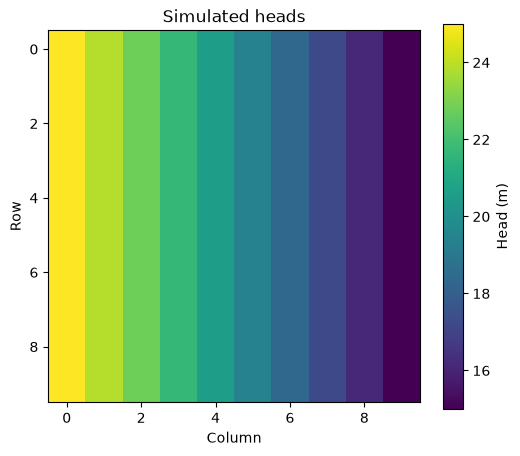

In [7]:
# Cell 7: Read and plot the results
head = gwf.output.head().get_data()[0]     # shape (10, 10)
print(head.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(head, cmap="viridis")
fig.colorbar(im, ax=ax, label="Head (m)")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title("Simulated heads")
plt.show()

In [8]:
expected = np.linspace(25, 15, 10)
print(np.allclose(head[0], expected, atol=1e-3))
print("Largest difference:", np.abs(head[0] - expected).max())

True
Largest difference: 1.1648081461146376e-05


In [11]:
def darcy_discharge(K, i, A):
    return K * i * A

K = 5.0                      # m/day
gradient = (25 - 15) / 900   # head drop / distance between first and last cell centres
area = 100.0 * 10.0          # row width (m) x aquifer thickness (m)

Q_row = darcy_discharge(K, gradient, area)
print(f"Flow through one row: {Q_row:.2f} m3/day")
print(f"Flow through all 10 rows: {10 * Q_row:.1f} m3/day")

Flow through one row: 55.56 m3/day
Flow through all 10 rows: 555.6 m3/day
